# CEO AI — Rapport ML du projet

**Cours :** Machine Learning  
**Projet :** évaluation d'idées de business et analyse de projets existants  
**Auteur :** étudiant(e) — à compléter  
**Date :** 2026

Ce notebook présente :

1. le jeu de données **synthétique documenté** (6 000 idées) ;
2. l'analyse exploratoire (EDA) ;
3. la comparaison des classifieurs et régresseurs ;
4. les métriques de test, la matrice de confusion, la courbe ROC ;
5. l'importance des variables et SHAP ;
6. la segmentation KMeans ;
7. les conclusions et limites.

> Important : le jeu de données fourni est **synthétique**. Il est généré à partir
> d'hypothèses sectorielles documentées dans `configs/markets.yaml` (marges,
> concurrence, intensité capitalistique, croissance, risque réglementaire...).
> Il ne s'agit pas de données d'entreprises réelles. Le code accepte aussi un vrai
> dataset CSV/XLSX placé dans `data/` avec le même schéma.

In [1]:
from pathlib import Path
import json
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path.cwd()
if not (ROOT / "models").exists():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 5)
print("Racine du projet :", ROOT)

Racine du projet : C:\chat-bot


## 1. Chargement et contrôle du dataset

Le schéma cible contient 21 variables explicatives et 3 cibles :

- `success` : classification binaire ;
- `roi_percent` : régression ;
- `breakeven_months` : régression.

In [2]:
df = pd.read_csv(ROOT / "data" / "synthetic_businesses.csv")
print(f"Dimensions : {df.shape[0]:,} lignes × {df.shape[1]} colonnes")
print(f"Taux de succès : {df['success'].mean():.1%}")
display(df.head(3))
display(df.dtypes.to_frame("dtype"))
display(df.describe(include="all").T.head(30))

Dimensions : 6,000 lignes × 27 colonnes
Taux de succès : 59.0%


,idea_id,sector,target_market,revenue_model,funding_stage,country_preset,country,city,city_tier,budget,...,operational_complexity,regulatory_risk,timing_score,marketing_spend,expected_customers,founder_experience_years,team_readiness,success,roi_percent,breakeven_months
0,IDEA-000001,fintech,b2c,hybrid,seed,generic,Generic,Capital city,3,76758.16,...,6.50,8.60,7.23,4447.22,165,4.43,6.53,1,99.10,15.05
1,IDEA-000002,renewable_energy,b2b,one_time,seed,generic,Generic,Regional city,3,119869.87,...,7.49,8.36,8.78,2728.30,25,4.12,7.01,1,-95.00,60.00
2,IDEA-000003,retail,b2c,one_time,friends_family,tunisia,Tunisia,Sousse,1,29250.31,...,6.12,5.71,4.93,2131.42,317,6.69,4.97,1,77.63,18.33


,dtype
idea_id,object
sector,object
target_market,object
revenue_model,object
funding_stage,object
country_preset,object
country,object
city,object
city_tier,int64
budget,float64


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
idea_id,6000,6000,IDEA-005984,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sector,6000,16,food_beverage,669,NaN,NaN,NaN,NaN,NaN,NaN,NaN
target_market,6000,4,b2c,3090,NaN,NaN,NaN,NaN,NaN,NaN,NaN
revenue_model,6000,6,one_time,3084,NaN,NaN,NaN,NaN,NaN,NaN,NaN
funding_stage,6000,4,friends_family,2753,NaN,NaN,NaN,NaN,NaN,NaN,NaN
country_preset,6000,2,tunisia,3816,NaN,NaN,NaN,NaN,NaN,NaN,NaN
country,6000,2,Tunisia,3816,NaN,NaN,NaN,NaN,NaN,NaN,NaN
city,6000,8,Sousse,803,NaN,NaN,NaN,NaN,NaN,NaN,NaN
city_tier,6000.0,NaN,NaN,NaN,1.726833,0.770917,1.0,1.0,2.0,2.0,3.0
budget,5960.0,NaN,NaN,NaN,52103.492438,42298.166923,2500.0,24625.5,40684.735,65362.285,489260.72


### 1.1 Valeurs manquantes

Quelques valeurs manquantes ont été injectées volontairement (budget, taille
d'équipe, expérience du fondateur, marketing) pour rendre l'imputation du
pipeline réellement utile.

In [3]:
missing = df.isna().sum().sort_values(ascending=False)
missing = missing[missing > 0]
display(missing.to_frame("valeurs_manquantes"))

,valeurs_manquantes
budget,40
founder_experience_years,35
marketing_spend,31
team_size,24


## 2. Analyse exploratoire (EDA)

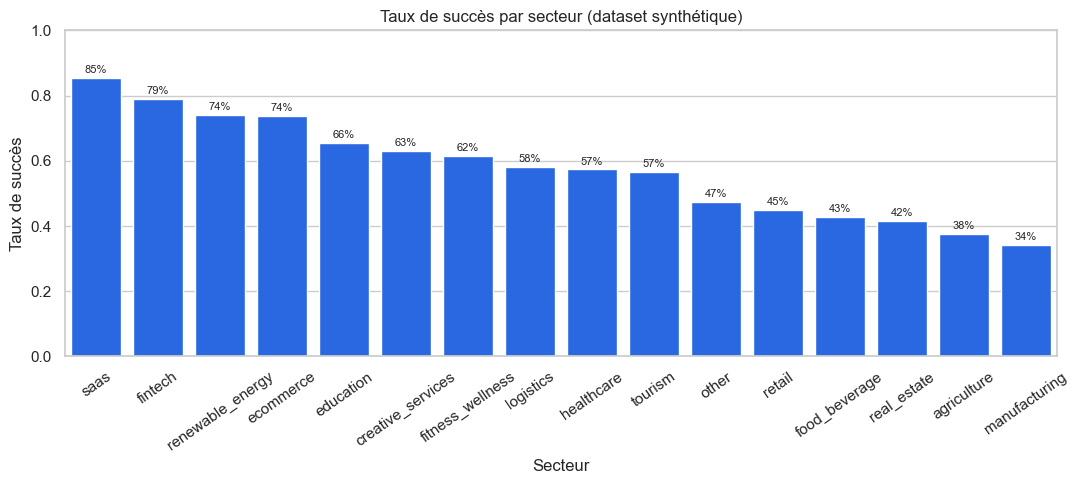

,mean,count
sector,,
saas,0.854,548
fintech,0.790,286
renewable_energy,0.740,269
ecommerce,0.738,596
education,0.656,465
creative_services,0.631,396
fitness_wellness,0.616,237
logistics,0.582,263
healthcare,0.574,340


In [4]:
sector_success = (
    df.groupby("sector")["success"]
    .agg(["mean", "count"])
    .sort_values("mean", ascending=False)
)
fig, ax = plt.subplots(figsize=(11, 5))
sns.barplot(x=sector_success.index, y=sector_success["mean"], ax=ax, color="#0B5FFF")
ax.set_title("Taux de succès par secteur (dataset synthétique)")
ax.set_ylabel("Taux de succès")
ax.set_xlabel("Secteur")
ax.set_ylim(0, 1)
ax.tick_params(axis="x", rotation=35)
for i, value in enumerate(sector_success["mean"]):
    ax.text(i, value + 0.015, f"{value:.0%}", ha="center", fontsize=8)
plt.tight_layout()
plt.show()
display(sector_success.round(3))

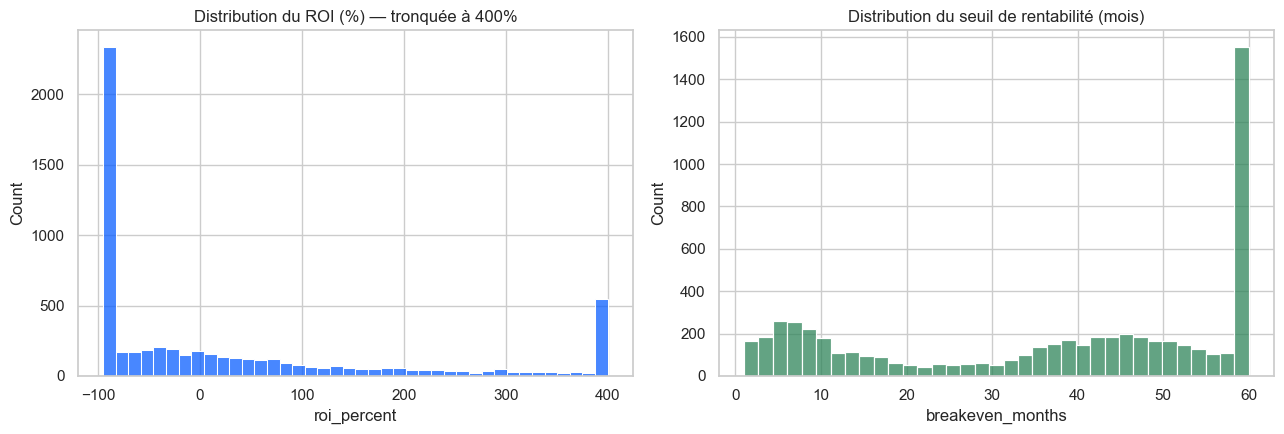

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(df["roi_percent"].clip(-100, 400), bins=40, ax=axes[0], color="#0B5FFF")
axes[0].set_title("Distribution du ROI (%) — tronquée à 400%")
sns.histplot(df["breakeven_months"], bins=35, ax=axes[1], color="#2F855A")
axes[1].set_title("Distribution du seuil de rentabilité (mois)")
plt.tight_layout()
plt.show()

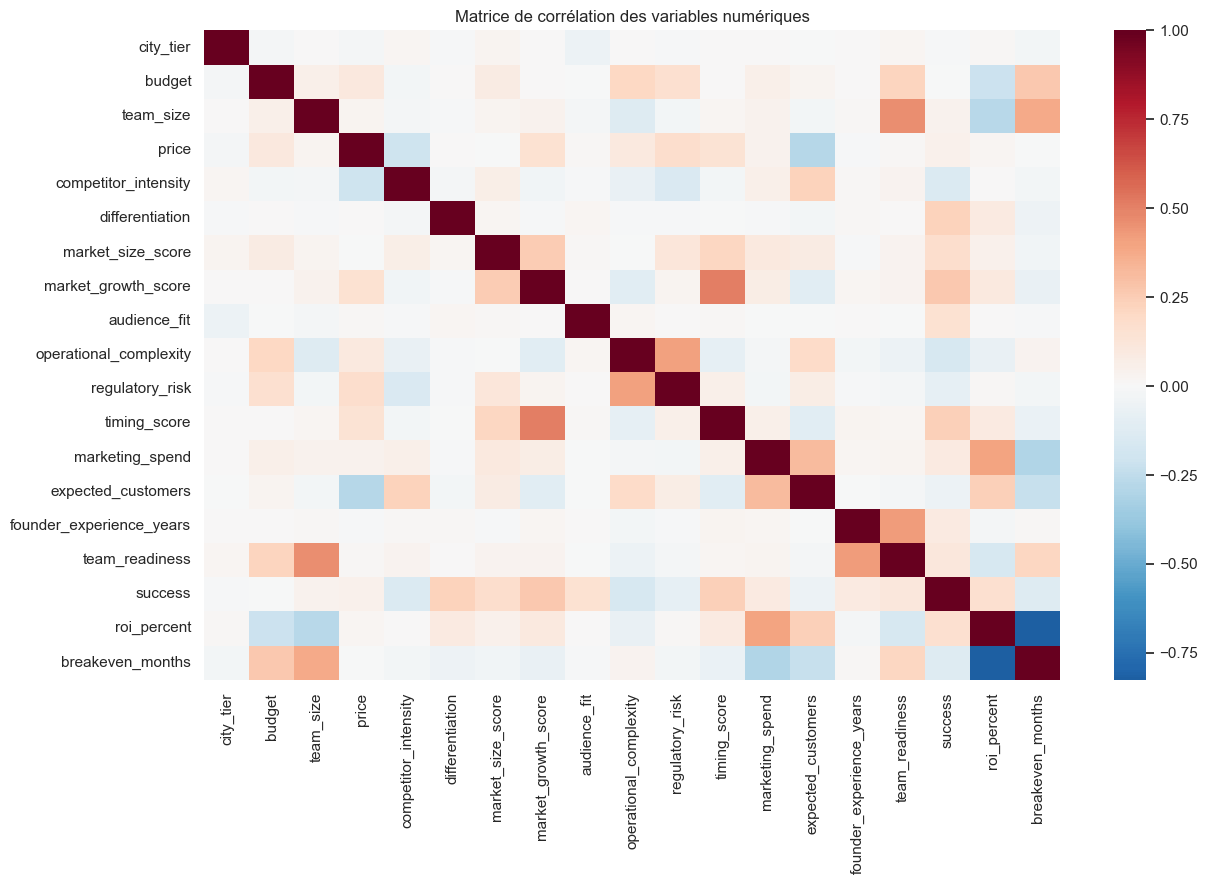

Corrélations avec success :


,corrélation
market_growth_score,0.268783
timing_score,0.242057
differentiation,0.233383
market_size_score,0.176039
roi_percent,0.165510
operational_complexity,-0.163470
audience_fit,0.154209
competitor_intensity,-0.141352
breakeven_months,-0.132657
team_readiness,0.109681


In [6]:
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
numeric_cols = [c for c in numeric_cols if c not in ("idea_id",)]
corr = df[numeric_cols].corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(13, 9))
sns.heatmap(corr, cmap="RdBu_r", center=0, annot=False, ax=ax)
ax.set_title("Matrice de corrélation des variables numériques")
plt.tight_layout()
plt.show()

print("Corrélations avec success :")
display(corr["success"].drop("success").sort_values(key=abs, ascending=False).head(12).to_frame("corrélation"))

## 3. Comparaison des modèles

Le pipeline scikit-learn enchaîne :

1. `SimpleImputer` (médiane / mode) ;
2. `StandardScaler` pour les variables numériques ;
3. `OneHotEncoder(handle_unknown="ignore")` pour les variables catégorielles ;
4. le modèle (régression logistique, Random Forest, Gradient Boosting, XGBoost).

La validation croisée est stratifiée pour la classification et standard pour la
régression. Le meilleur modèle de base est ensuite optimisé avec
`RandomizedSearchCV`.

In [7]:
metrics = json.loads((ROOT / "models" / "metadata.json").read_text(encoding="utf-8"))
comparison = pd.read_csv(ROOT / "models" / "model_comparison.csv")

cls = comparison[comparison["kind"] == "classification"].copy()
cols = ["model", "accuracy_mean", "precision_mean", "recall_mean", "f1_mean", "roc_auc_mean", "roc_auc_std", "fit_seconds"]
display(cls[cols].sort_values("roc_auc_mean", ascending=False).round(4))
print("Meilleur classifieur :", metrics["classification"]["best_model"])
print("Métriques de test :", {k: round(v, 4) for k, v in metrics["classification"]["test_metrics"].items() if isinstance(v, (int, float))})

,model,accuracy_mean,precision_mean,recall_mean,f1_mean,roc_auc_mean,roc_auc_std,fit_seconds
4,Tuned Logistic Regression (baseline),0.7133,0.7855,0.7067,0.7439,0.7914,0.0078,5.61
0,Logistic Regression (baseline),0.7152,0.7868,0.7088,0.7457,0.7902,0.0072,1.28
3,XGBoost,0.7131,0.7383,0.7954,0.7657,0.7763,0.0050,10.77
1,Random Forest,0.7127,0.7227,0.8322,0.7735,0.7763,0.0055,10.14
2,Gradient Boosting,0.7146,0.7371,0.8021,0.7681,0.7752,0.0055,20.32


Meilleur classifieur : Tuned Logistic Regression (baseline)
Métriques de test : {'accuracy': 0.7208, 'precision': 0.7891, 'recall': 0.7189, 'f1': 0.7524, 'roc_auc': 0.79}


In [8]:
reg = comparison[comparison["kind"] == "regression"].copy()
for target in ("roi_percent", "breakeven_months"):
    print(f"\n### Cible : {target}")
    subset = reg[reg["target"] == target]
    display(subset[["model", "mae_mean", "rmse_mean", "r2_mean", "fit_seconds"]].sort_values("mae_mean").round(4))
    print("Métriques de test :", {k: round(v, 4) for k, v in metrics["regression"][target]["metrics"].items() if isinstance(v, (int, float))})


### Cible : roi_percent


,model,mae_mean,rmse_mean,r2_mean,fit_seconds
9,Tuned XGBoost Regressor,62.1553,96.3547,0.7807,55.10
8,XGBoost Regressor,68.0275,102.5219,0.7515,4.41
7,Gradient Boosting Regressor,76.4073,113.2422,0.6973,21.38
6,Random Forest Regressor,77.1164,120.3746,0.6578,11.11
5,Ridge Regression (baseline),106.7587,147.8122,0.4841,0.57


Métriques de test : {'mae': 54.6165, 'rmse': 85.4557, 'r2': 0.811, 'mape': 113.4228}

### Cible : breakeven_months


,model,mae_mean,rmse_mean,r2_mean,fit_seconds
14,Tuned XGBoost Regressor,7.8439,10.6528,0.7366,39.56
13,XGBoost Regressor,8.2039,11.0314,0.7175,3.88
12,Gradient Boosting Regressor,8.7816,11.6618,0.6842,19.32
11,Random Forest Regressor,9.0671,12.2471,0.6518,7.78
10,Ridge Regression (baseline),11.0680,13.8230,0.5563,0.31


Métriques de test : {'mae': 7.4184, 'rmse': 10.3014, 'r2': 0.749, 'mape': 47.5266}


## 4. Évaluation sur le jeu de test

### 4.1 Matrice de confusion et courbe ROC

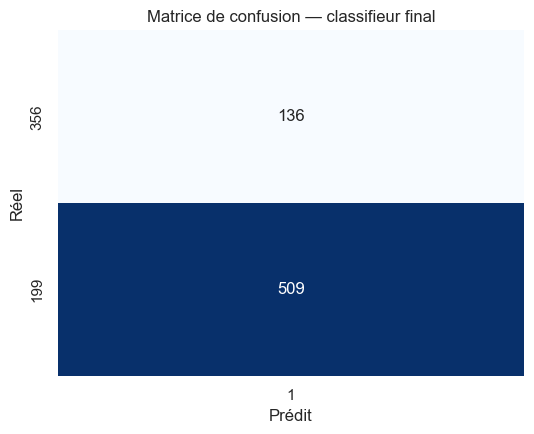

,1
0,
356,136
199,509


In [9]:
cm = pd.read_csv(ROOT / "models" / "confusion_matrix.csv", index_col=0)
fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
ax.set_title("Matrice de confusion — classifieur final")
ax.set_xlabel("Prédit")
ax.set_ylabel("Réel")
plt.tight_layout()
plt.show()
display(cm)

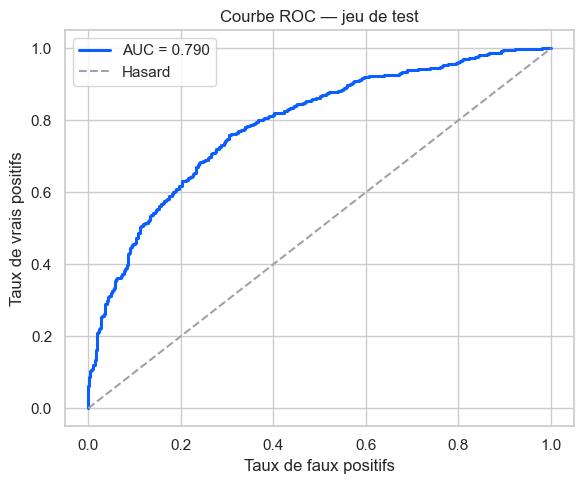

In [10]:
roc = pd.read_csv(ROOT / "models" / "roc_curve.csv")
auc = metrics["classification"]["test_metrics"]["roc_auc"]
fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(roc["fpr"], roc["tpr"], color="#0B5FFF", linewidth=2.2, label=f"AUC = {auc:.3f}")
ax.plot([0, 1], [0, 1], "--", color="#9CA3AF", label="Hasard")
ax.set_xlabel("Taux de faux positifs")
ax.set_ylabel("Taux de vrais positifs")
ax.set_title("Courbe ROC — jeu de test")
ax.legend()
plt.tight_layout()
plt.show()

### 4.2 Régression : prédit vs réel

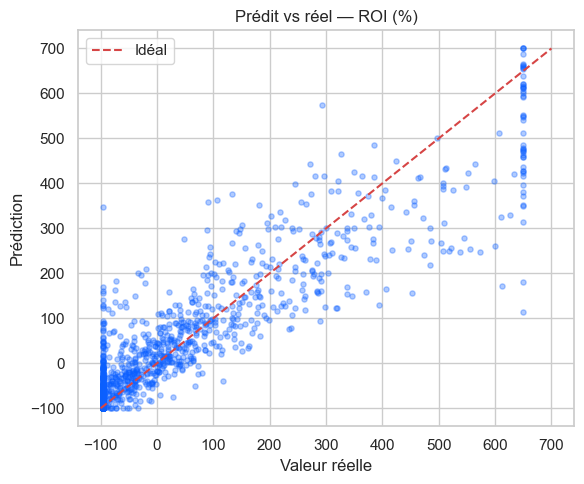

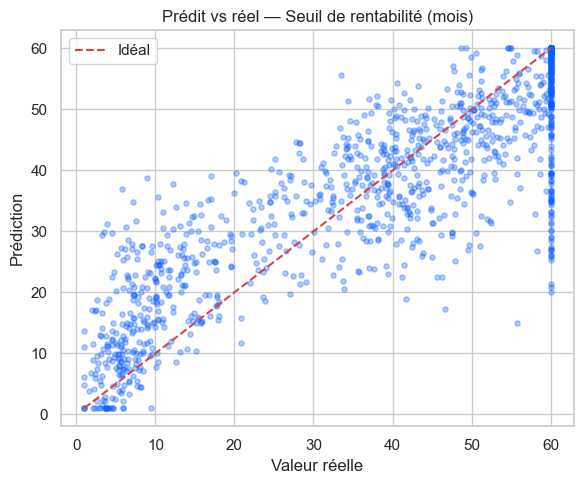

In [11]:
for suffix, title in (("roi", "ROI (%)"), ("breakeven", "Seuil de rentabilité (mois)")):
    pred = pd.read_csv(ROOT / "models" / f"test_predictions_{suffix}.csv")
    fig, ax = plt.subplots(figsize=(6, 5))
    ax.scatter(pred["y_true"], pred["y_pred"], alpha=0.32, s=14, color="#0B5FFF")
    low = min(pred["y_true"].min(), pred["y_pred"].min())
    high = max(pred["y_true"].max(), pred["y_pred"].max())
    ax.plot([low, high], [low, high], "--", color="#D64545", label="Idéal")
    ax.set_xlabel("Valeur réelle")
    ax.set_ylabel("Prédiction")
    ax.set_title(f"Prédit vs réel — {title}")
    ax.legend()
    plt.tight_layout()
    plt.show()

## 5. Interprétabilité

L'importance par permutation mesure la baisse de performance quand une variable
est mélangée. SHAP fournit en plus une explication locale : le chatbot peut donc
dire quels facteurs poussent le score vers le haut ou vers le bas.

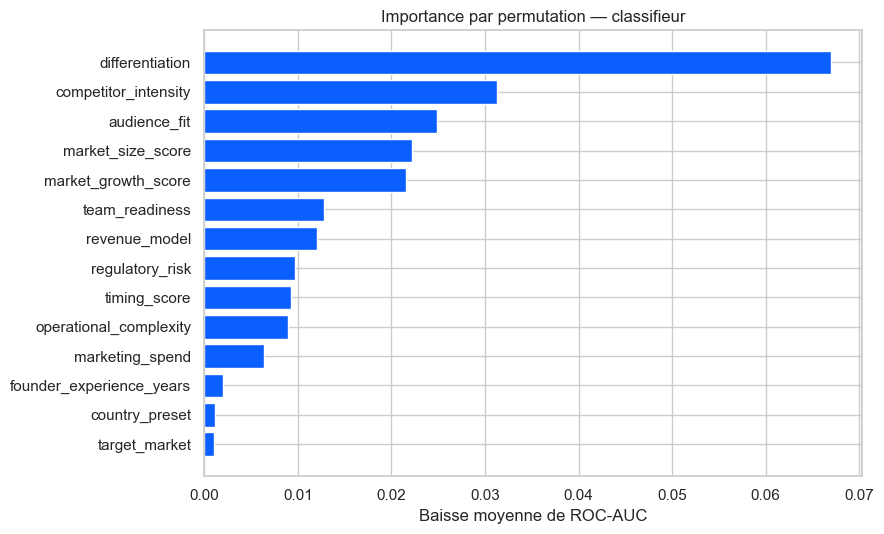

,feature,importance_mean,importance_std
0,differentiation,0.0670,0.0087
1,competitor_intensity,0.0313,0.0046
2,audience_fit,0.0248,0.0035
3,market_size_score,0.0222,0.0023
4,market_growth_score,0.0215,0.0038
5,team_readiness,0.0128,0.0026
6,revenue_model,0.0120,0.0038
7,regulatory_risk,0.0097,0.0023
8,timing_score,0.0093,0.0013
9,operational_complexity,0.0090,0.0025


In [12]:
importance = pd.read_csv(ROOT / "models" / "feature_importance_classification.csv")
top = importance.head(14).sort_values("importance_mean")
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(top["feature"], top["importance_mean"], color="#0B5FFF")
ax.set_title("Importance par permutation — classifieur")
ax.set_xlabel("Baisse moyenne de ROC-AUC")
plt.tight_layout()
plt.show()
display(importance.head(12).round(4))

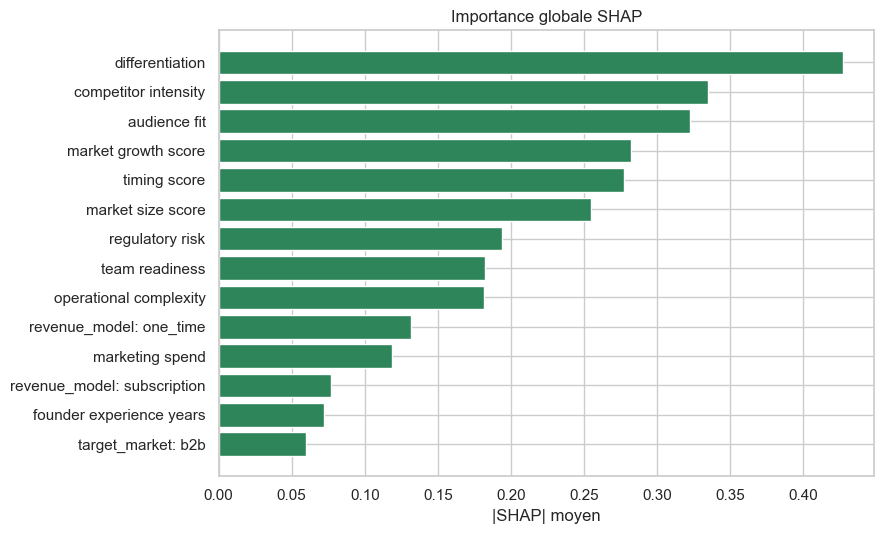

,feature,display,mean_abs_shap
13,target_market,target_market: b2b,0.0597
12,founder_experience_years,founder experience years,0.0720
11,revenue_model,revenue_model: subscription,0.0769
10,marketing_spend,marketing spend,0.1188
9,revenue_model,revenue_model: one_time,0.1318
8,operational_complexity,operational complexity,0.1813
7,team_readiness,team readiness,0.1823
6,regulatory_risk,regulatory risk,0.1942
5,market_size_score,market size score,0.2546
4,timing_score,timing score,0.2775


In [13]:
shap_path = ROOT / "models" / "shap_importance.csv"
if shap_path.exists():
    shap_df = pd.read_csv(shap_path).head(14).sort_values("mean_abs_shap")
    fig, ax = plt.subplots(figsize=(9, 5.5))
    ax.barh(shap_df["display"], shap_df["mean_abs_shap"], color="#2F855A")
    ax.set_title("Importance globale SHAP")
    ax.set_xlabel("|SHAP| moyen")
    plt.tight_layout()
    plt.show()
    display(shap_df.round(4))
else:
    print("SHAP non disponible : le rapport utilise l'importance par permutation.")

## 6. Segmentation KMeans des idées

Nombre de segments : 5


,cluster,market_size_score,market_growth_score,audience_fit,competitor_intensity,differentiation,budget,team_readiness,success,roi_percent,segment_name
0,0,8.070,5.979,6.437,7.128,6.063,153100.900,6.127,0.641,-31.355,Strong differentiated niche
1,1,8.720,7.907,6.451,6.565,6.164,44133.071,5.232,0.818,88.308,High-potential growth play
2,2,7.675,5.212,7.201,7.867,7.378,39189.678,4.859,0.619,74.367,Balanced opportunity
3,3,8.175,5.936,5.964,8.465,4.472,46163.470,5.699,0.447,28.791,Competitive execution play
4,4,6.776,5.073,6.152,6.199,5.064,41308.436,4.861,0.461,36.731,High-risk early concept


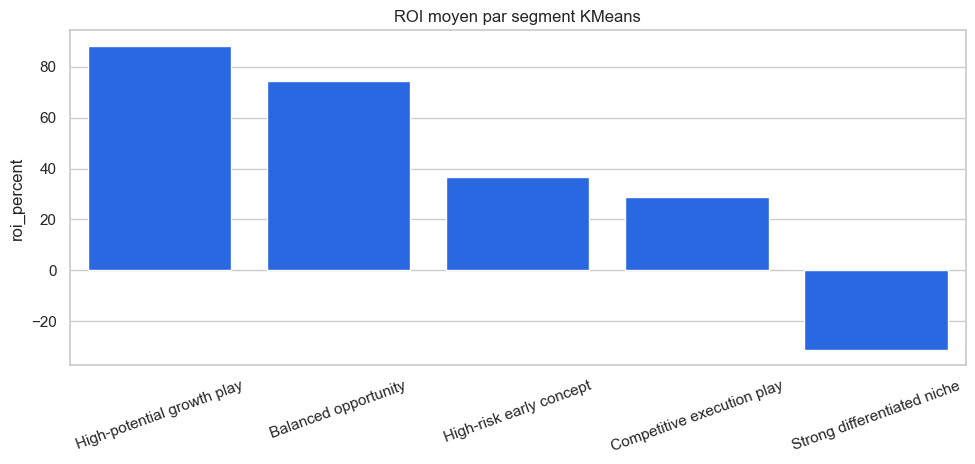

In [14]:
kmeans = metrics["clustering"]
print("Nombre de segments :", kmeans["n_clusters"])
profiles = pd.DataFrame(kmeans["profiles"])
display(profiles.round(3))

fig, ax = plt.subplots(figsize=(10, 4.8))
plot_df = profiles.sort_values("roi_percent", ascending=False)
sns.barplot(data=plot_df, x="segment_name", y="roi_percent", ax=ax, color="#0B5FFF", errorbar=None)
ax.set_title("ROI moyen par segment KMeans")
ax.set_xlabel("")
ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

## 7. Conclusions

### Ce qui fonctionne

- Le pipeline est **reproductible** et sauvegardé avec `joblib`.
- La classification atteint un **ROC-AUC proche de 0,79** sur le test, avec un
  rappel et un F1 équilibrés. La régression ROI atteint un **R² proche de 0,81** ;
  le seuil de rentabilité un **R² proche de 0,75**.
- Les variables les plus utiles sont cohérentes avec la théorie business :
  différenciation, taille/croissance du marché, intensité concurrentielle,
  préparation de l'équipe et modèle de revenus.
- SHAP permet des explications locales, utilisées directement dans le chatbot.

### Limites

- Le dataset est **synthétique** : les relations apprises reflètent les hypothèses
  du générateur, pas nécessairement l'économie réelle.
- Le ROI et le seuil de rentabilité sont des estimations ; ils ne remplacent pas
  une étude de marché ou un conseil financier.
- Les données réelles, si elles sont fournies, doivent respecter le même schéma
  et peuvent nécessiter un recalibrage.
- Le succès est un concept bruité : même un bon modèle reste un outil d'aide à la
  décision, avec une incertitude explicite.

### Pistes d'amélioration

1. Remplacer le dataset synthétique par des données réelles (Kaggle, incubateurs).
2. Ajouter une calibration probabiliste (`CalibratedClassifierCV`, courbe de fiabilité).
3. Tester LightGBM/CatBoost et des modèles temporels plus avancés (Prophet, ARIMA).
4. Ajouter une validation temporelle pour les prévisions.
5. Mettre en place un suivi de dérive (data drift) en production.

In [15]:
print("Résumé final")
print("-" * 60)
print(f"Classifieur : {metrics['classification']['best_model']}")
print(f"ROC-AUC test : {metrics['classification']['test_metrics']['roc_auc']:.3f}")
print(f"F1 test : {metrics['classification']['test_metrics']['f1']:.3f}")
for target in ("roi_percent", "breakeven_months"):
    m = metrics["regression"][target]["metrics"]
    print(f"{target} : MAE={m['mae']:.2f} | R2={m['r2']:.3f}")
print("Dataset : synthétique,", metrics["dataset"]["rows"], "lignes")

Résumé final
------------------------------------------------------------
Classifieur : Tuned Logistic Regression (baseline)
ROC-AUC test : 0.790
F1 test : 0.752
roi_percent : MAE=54.62 | R2=0.811
breakeven_months : MAE=7.42 | R2=0.749
Dataset : synthétique, 6000 lignes
